In [ ]:
!pip install -q kagglehub imbalanced-learn
!pip install -q xgboost catboost


import os
import glob
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.svm import SVC

from sklearn.neighbors import KNeighborsClassifier

from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Dense,
    Dropout
)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
tf.keras.utils.set_random_seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
warnings.filterwarnings("ignore")

In [ ]:
import kagglehub


dataset_path = kagglehub.dataset_download(
    "uom190346a/water-quality-and-potability"
)

# Mencari file CSV
csv_files = glob.glob(
    os.path.join(dataset_path, "**", "*.csv"),
    recursive=True
)

print("File dataset ditemukan:", csv_files)

df = pd.read_csv(csv_files[0])

print("Ukuran dataset:", df.shape)
display(df.head())

100%|██████████| 251k/251k [00:00<00:00, 51.7MB/s]

Extracting files...
File dataset ditemukan: ['/root/.cache/kagglehub/datasets/uom190346a/water-quality-and-potability/versions/2/water_potability.csv']
Ukuran dataset: (3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [ ]:
display(df.info())
display(df.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


None

,count,mean,std,min,25%,50%,75%,max
ph,2785.0,7.080795,1.594320,0.000000,6.093092,7.036752,8.062066,14.000000
Hardness,3276.0,196.369496,32.879761,47.432000,176.850538,196.967627,216.667456,323.124000
Solids,3276.0,22014.092526,8768.570828,320.942611,15666.690297,20927.833607,27332.762127,61227.196008
Chloramines,3276.0,7.122277,1.583085,0.352000,6.127421,7.130299,8.114887,13.127000
Sulfate,2495.0,333.775777,41.416840,129.000000,307.699498,333.073546,359.950170,481.030642
Conductivity,3276.0,426.205111,80.824064,181.483754,365.734414,421.884968,481.792304,753.342620
Organic_carbon,3276.0,14.284970,3.308162,2.200000,12.065801,14.218338,16.557652,28.300000
Trihalomethanes,3114.0,66.396293,16.175008,0.738000,55.844536,66.622485,77.337473,124.000000
Turbidity,3276.0,3.966786,0.780382,1.450000,3.439711,3.955028,4.500320,6.739000
Potability,3276.0,0.390110,0.487849,0.000000,0.000000,0.000000,1.000000,1.000000


In [ ]:
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])
print("\\nNama kolom:")
print(df.columns.tolist())

print("\\nTipe data:")
display(df.dtypes)

print("\\nJumlah data duplikat:", df.duplicated().sum())

Jumlah baris: 3276
Jumlah kolom: 10
\nNama kolom:
['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability']
\nTipe data:


,0
ph,float64
Hardness,float64
Solids,float64
Chloramines,float64
Sulfate,float64
Conductivity,float64
Organic_carbon,float64
Trihalomethanes,float64
Turbidity,float64
Potability,int64


\nJumlah data duplikat: 0


,count
Potability,
Tidak layak (0),1998
Layak (1),1278


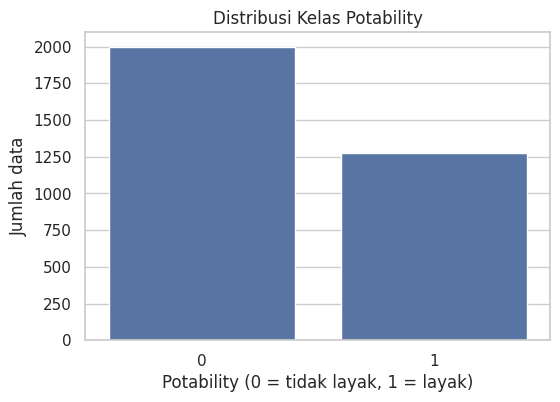

Proporsi kelas:


,proportion
Potability,
0,60.99
1,39.01


In [ ]:
target_counts = df["Potability"].value_counts().sort_index()
display(target_counts.rename(index={0: "Tidak layak (0)", 1: "Layak (1)"}))

plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="Potability")
ax.set_title("Distribusi Kelas Potability")
ax.set_xlabel("Potability (0 = tidak layak, 1 = layak)")
ax.set_ylabel("Jumlah data")
plt.show()

print("Proporsi kelas:")
display((df["Potability"].value_counts(normalize=True).sort_index() * 100).round(2))

In [ ]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
missing_table = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": missing_pct.round(2)
})
display(missing_table)

,missing_count,missing_percent
Sulfate,781,23.84
ph,491,14.99
Trihalomethanes,162,4.95
Hardness,0,0.00
Chloramines,0,0.00
Solids,0,0.00
Conductivity,0,0.00
Organic_carbon,0,0.00
Turbidity,0,0.00
Potability,0,0.00


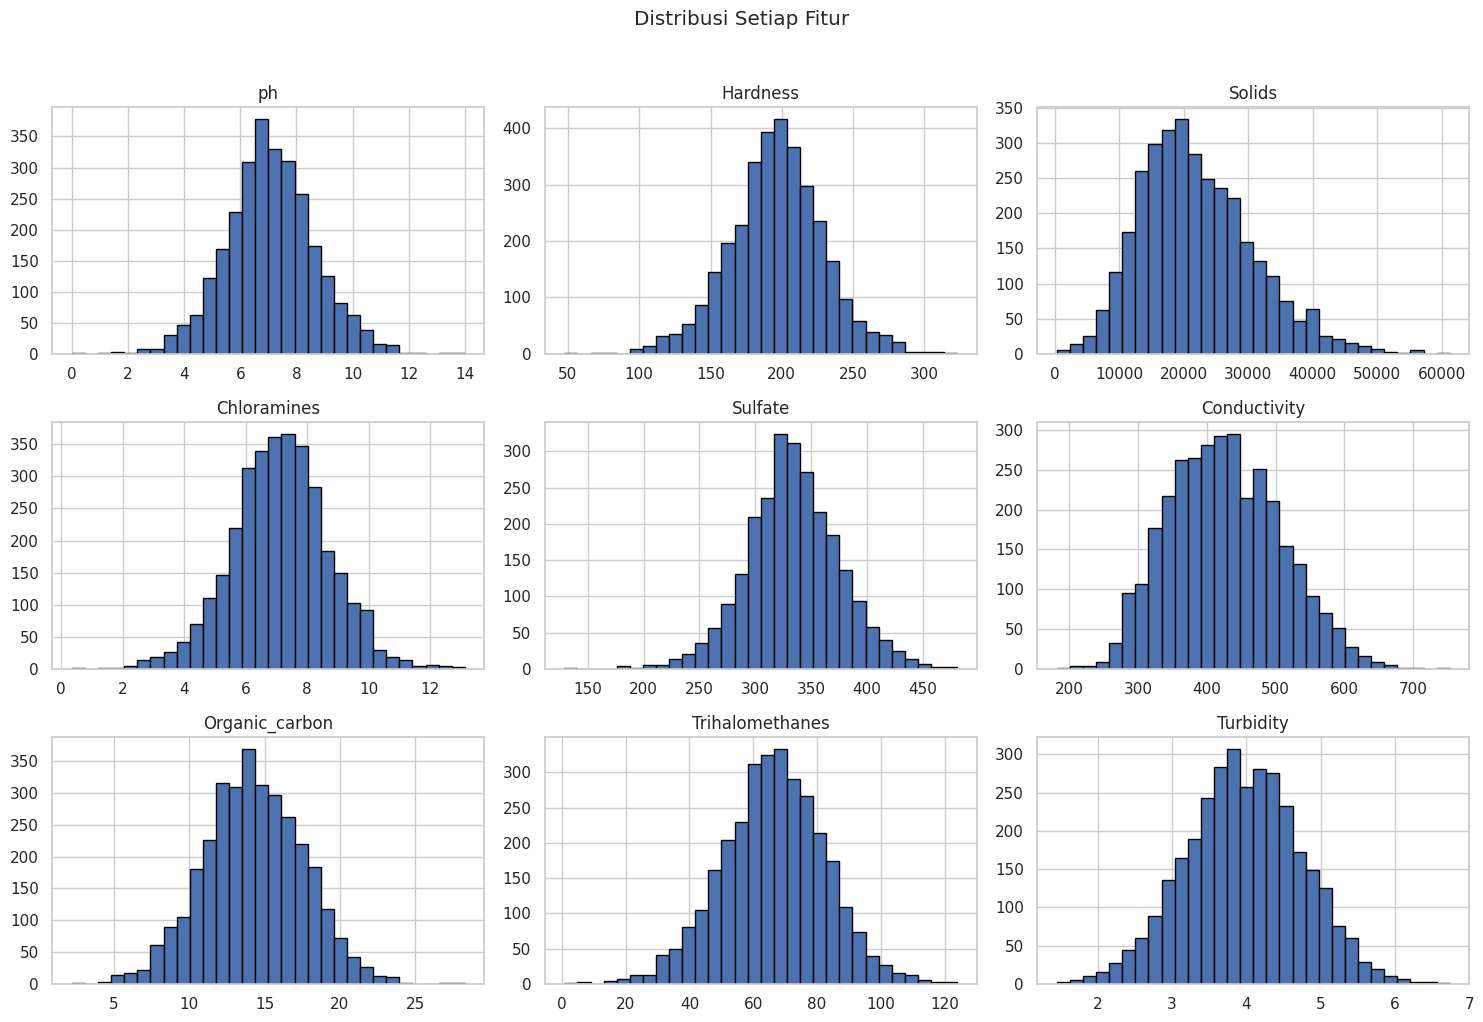

In [ ]:
feature_cols = [c for c in df.columns if c != "Potability"]

df[feature_cols].hist(figsize=(15, 10), bins=30, edgecolor="black")
plt.suptitle("Distribusi Setiap Fitur", y=1.02)
plt.tight_layout()
plt.show()

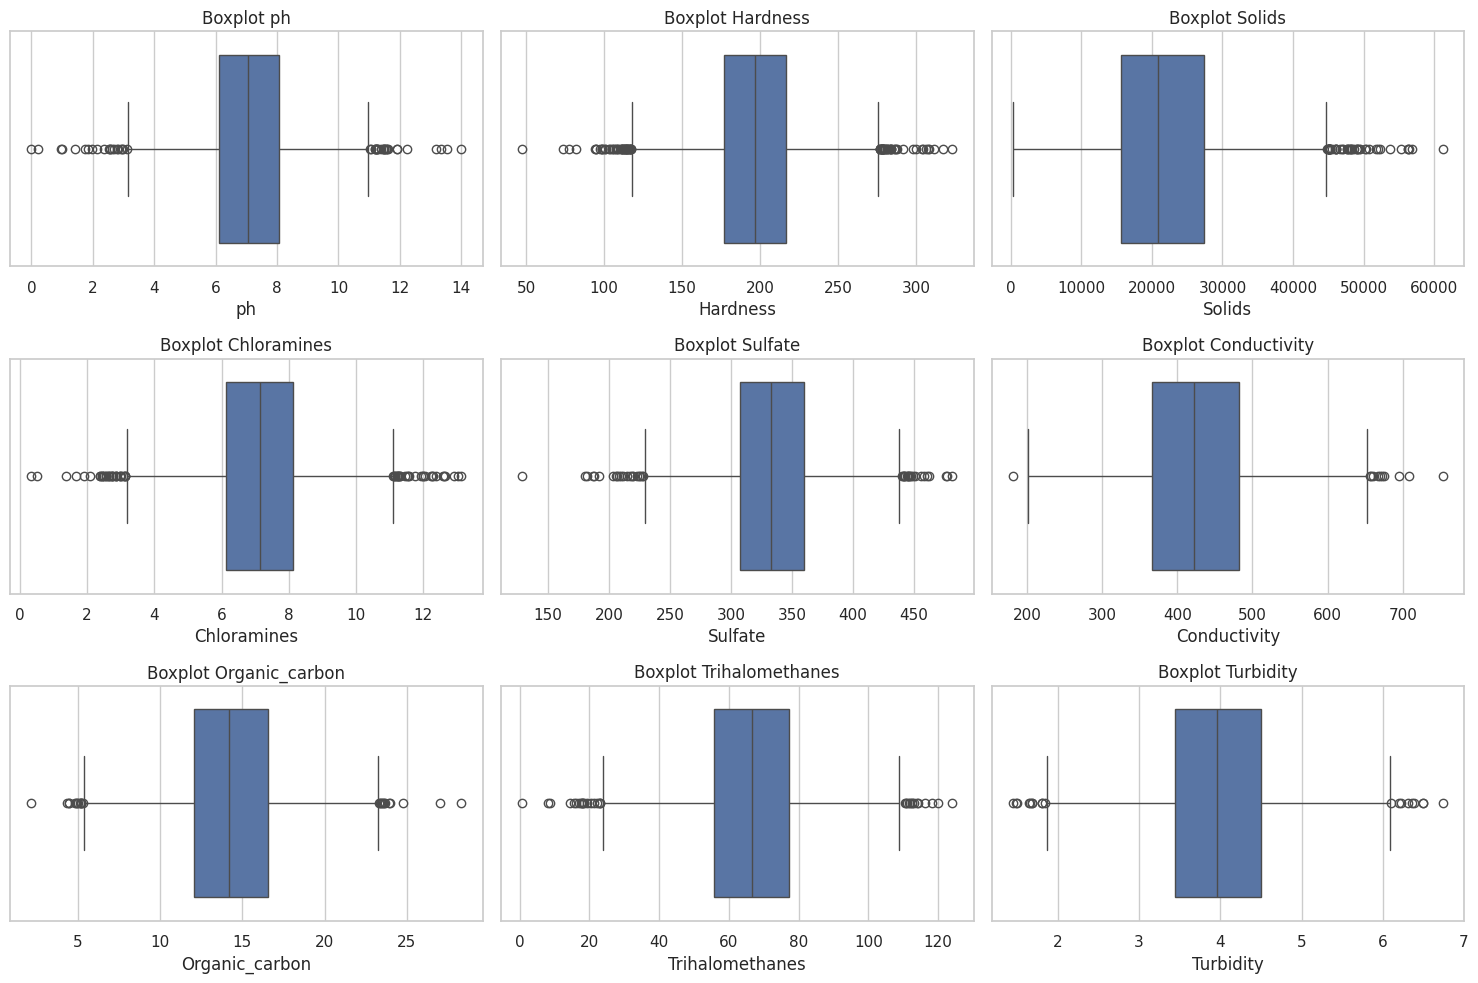

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.boxplot(x=df[col], ax=axes[i])
    axes[i].set_title(f"Boxplot {col}")

plt.tight_layout()
plt.show()

Berdasarkan visualisasi boxplot, ditemukan indikasi outlier pada seluruh fitur numerik. Identifikasi lebih lanjut dilakukan menggunakan metode IQR. Data ekstrem tetap dipertahankan karena belum tentu merupakan kesalahan pengukuran.

In [ ]:
outlier_results = []

for col in feature_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ][col]

    outlier_results.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outliers.count(),
        "Outlier Percentage": (
            outliers.count() / df[col].notna().sum()
        ) * 100
    })

outlier_df = pd.DataFrame(outlier_results)

display(outlier_df.round(2))

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,ph,3.14,11.02,46,1.65
1,Hardness,117.13,276.39,83,2.53
2,Solids,-1832.42,44831.87,47,1.43
3,Chloramines,3.15,11.10,61,1.86
4,Sulfate,229.32,438.33,41,1.64
5,Conductivity,191.65,655.88,11,0.34
6,Organic_carbon,5.33,23.30,25,0.76
7,Trihalomethanes,23.61,109.58,33,1.06
8,Turbidity,1.85,6.09,19,0.58


**Interpretasi Hasil Identifikasi Outlier**

Berdasarkan perhitungan menggunakan metode Interquartile Range (IQR), ditemukan kandidat outlier pada seluruh sembilan fitur numerik. Hardness memiliki jumlah kandidat outlier tertinggi sebanyak 83 data (2,53%), sedangkan Conductivity memiliki jumlah terendah sebanyak 11 data (0,34%). Seluruh fitur menunjukkan persentase kandidat outlier di bawah 3%. Oleh karena itu, data ekstrem tetap dipertahankan karena belum dapat dipastikan sebagai kesalahan pengukuran.

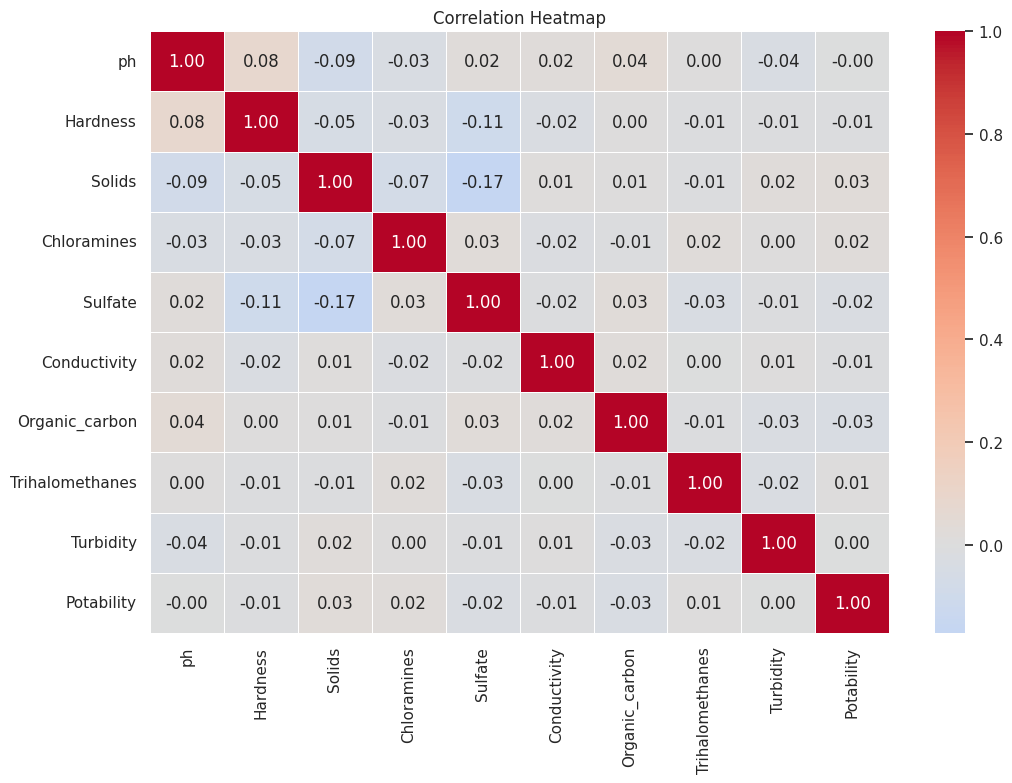

In [ ]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
target_corr = (
    corr["Potability"]
    .drop("Potability")
    .sort_values(key=abs, ascending=False)
)

display(target_corr.to_frame("Correlation with Potability"))

,Correlation with Potability
Solids,0.033743
Organic_carbon,-0.030001
Chloramines,0.023779
Sulfate,-0.023577
Hardness,-0.013837
Conductivity,-0.008128
Trihalomethanes,0.007130
ph,-0.003556
Turbidity,0.001581


**Interpretasi Correlation Heatmap**

Berdasarkan correlation heatmap, sebagian besar fitur memiliki korelasi linear yang sangat lemah. Korelasi tertinggi terhadap Potability terdapat pada fitur Solids sebesar 0,0337. Hal ini menunjukkan bahwa hubungan linear antara fitur dan target relatif lemah, sehingga kemungkinan terdapat pola non-linear yang perlu dianalisis lebih lanjut.

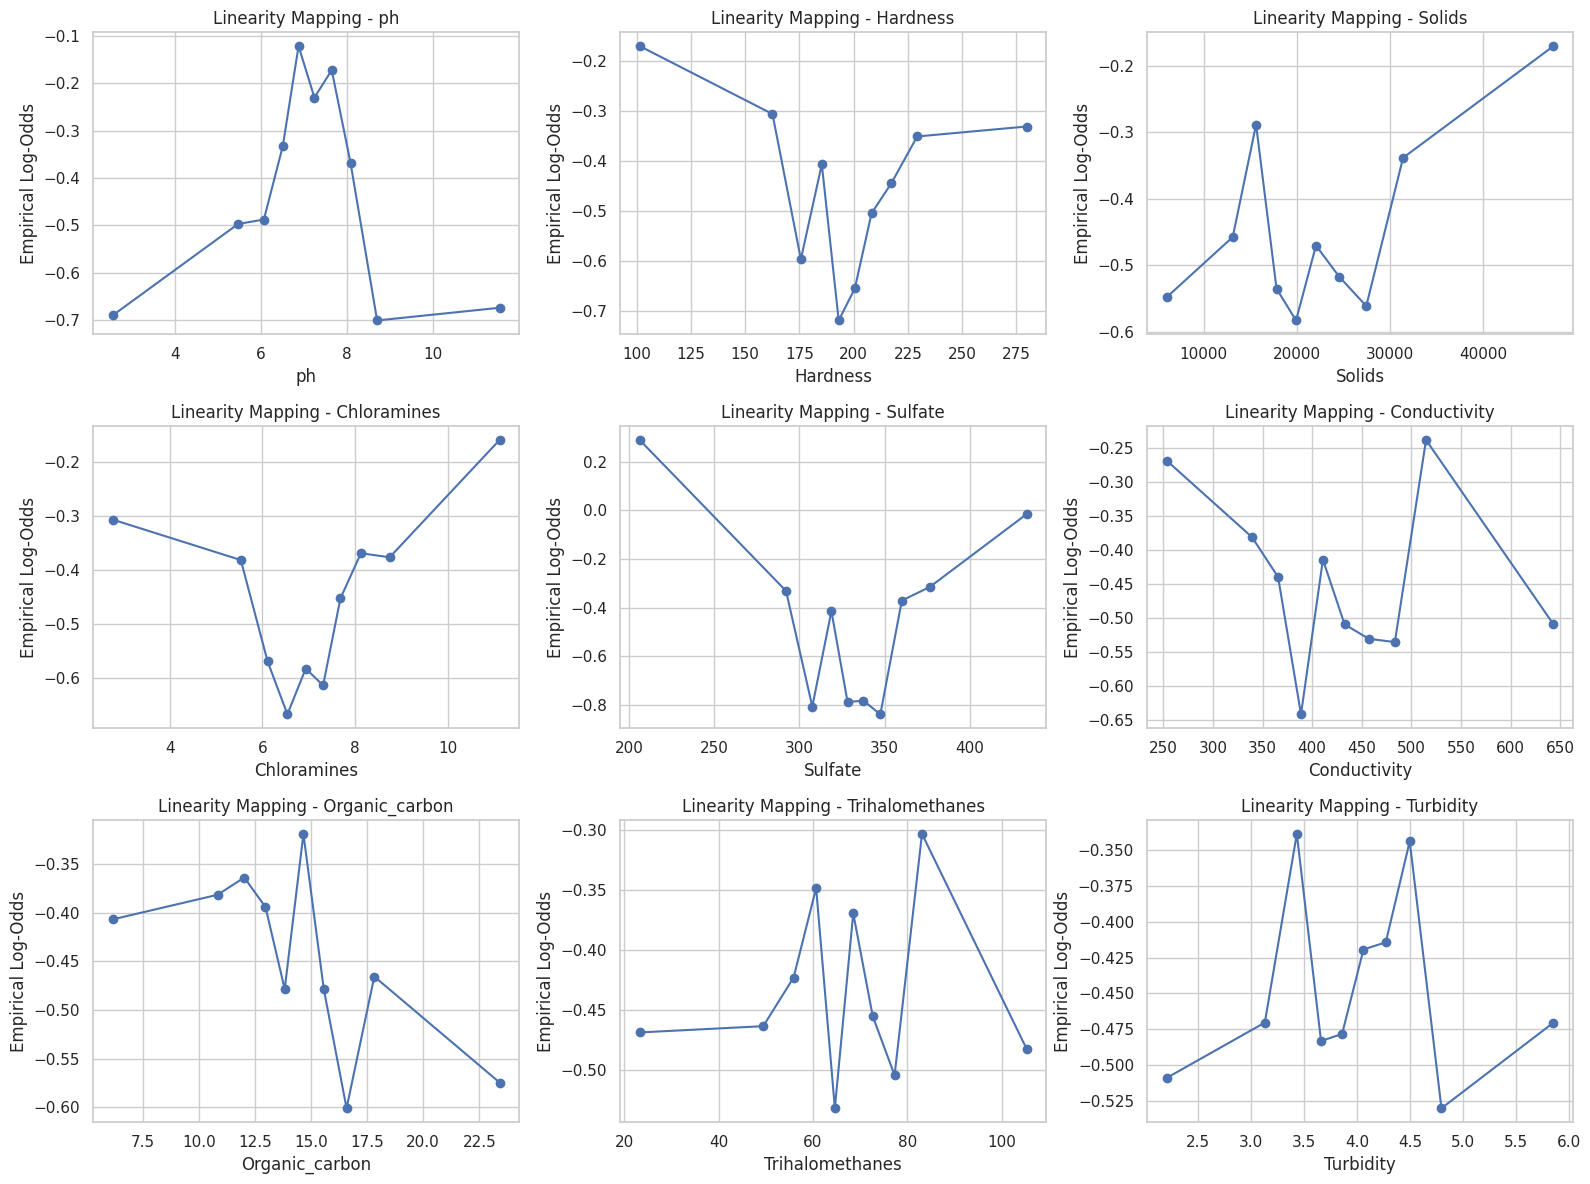

In [ ]:
def plot_binned_log_odds(data, feature, target="Potability", bins=10):

    temp = data[[feature, target]].dropna().copy()

    temp["bin"] = pd.qcut(
        temp[feature],
        q=bins,
        duplicates="drop"
    )

    summary = temp.groupby(
        "bin",
        observed=True
    )[target].agg(["count", "sum"])

    summary["non_event"] = (
        summary["count"] - summary["sum"]
    )

    summary["log_odds"] = np.log(
        (summary["sum"] + 0.5) /
        (summary["non_event"] + 0.5)
    )

    summary["bin_mid"] = [
        interval.mid for interval in summary.index
    ]

    plt.plot(
        summary["bin_mid"],
        summary["log_odds"],
        marker="o"
    )

    plt.xlabel(feature)
    plt.ylabel("Empirical Log-Odds")
    plt.title(f"Linearity Mapping - {feature}")


fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    plt.sca(axes[i])
    plot_binned_log_odds(df, col)

plt.tight_layout()
plt.show()

**Interpretasi Pemetaan Linearitas**

Berdasarkan hasil pemetaan linearitas, sebagian besar fitur menunjukkan pola hubungan yang tidak linear terhadap log-odds Potability. Grafik memperlihatkan perubahan yang berfluktuasi dan tidak membentuk pola garis lurus yang konsisten. Hal ini mengindikasikan bahwa hubungan antara fitur kualitas air dan target kemungkinan bersifat non-linear.

In [ ]:
df_model = df.drop_duplicates().copy()

X = df_model.drop(columns=["Potability"])
y = df_model["Potability"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

print("\\nProporsi kelas train:")
display(y_train.value_counts(normalize=True).sort_index().round(3))
print("\\nProporsi kelas test:")
display(y_test.value_counts(normalize=True).sort_index().round(3))

Train: (2620, 9)
Test : (656, 9)
\nProporsi kelas train:


,proportion
Potability,
0,0.61
1,0.39


\nProporsi kelas test:


,proportion
Potability,
0,0.61
1,0.39


In [ ]:
random_forest_pipeline = ImbPipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight=None,
        n_jobs=-1
    ))
])

svm_pipeline = ImbPipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=RANDOM_STATE
    ))
])

catboost_pipeline = ImbPipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", CatBoostClassifier(
        iterations=300,
        depth=6,
        learning_rate=0.05,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=RANDOM_STATE,
        verbose=0,
        allow_writing_files=False,
        auto_class_weights='Balanced',
    ))
])


models = {
    "Random Forest": random_forest_pipeline,
    "SVM": svm_pipeline,
    "CatBoost" : catboost_pipeline
}

In [ ]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name}: training selesai")

Random Forest: training selesai
SVM: training selesai
CatBoost: training selesai


In [ ]:
results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    predictions[name] = (y_pred, y_prob)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred,
            zero_division=0),
        "Recall": recall_score(
            y_test, y_pred,
            zero_division=0),
        "F1-score": f1_score(
            y_test, y_pred,
            zero_division=0),
        "ROC-AUC": roc_auc_score(
            y_test, y_prob),
        "PR-AUC": average_precision_score(
            y_test, y_prob)
    })


results_df = pd.DataFrame(
    results
).set_index("Model")
results_df = results_df.sort_values(
    by="F1-score",
    ascending=False
)
print("HASIL PERBANDINGAN ALGORITMA")

display(results_df.round(4))

HASIL PERBANDINGAN ALGORITMA


,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
Model,,,,,,
CatBoost,0.6479,0.5506,0.5312,0.5408,0.6799,0.6204
Random Forest,0.6555,0.5658,0.5039,0.5331,0.6790,0.6070
SVM,0.6143,0.5054,0.5469,0.5253,0.6541,0.5667


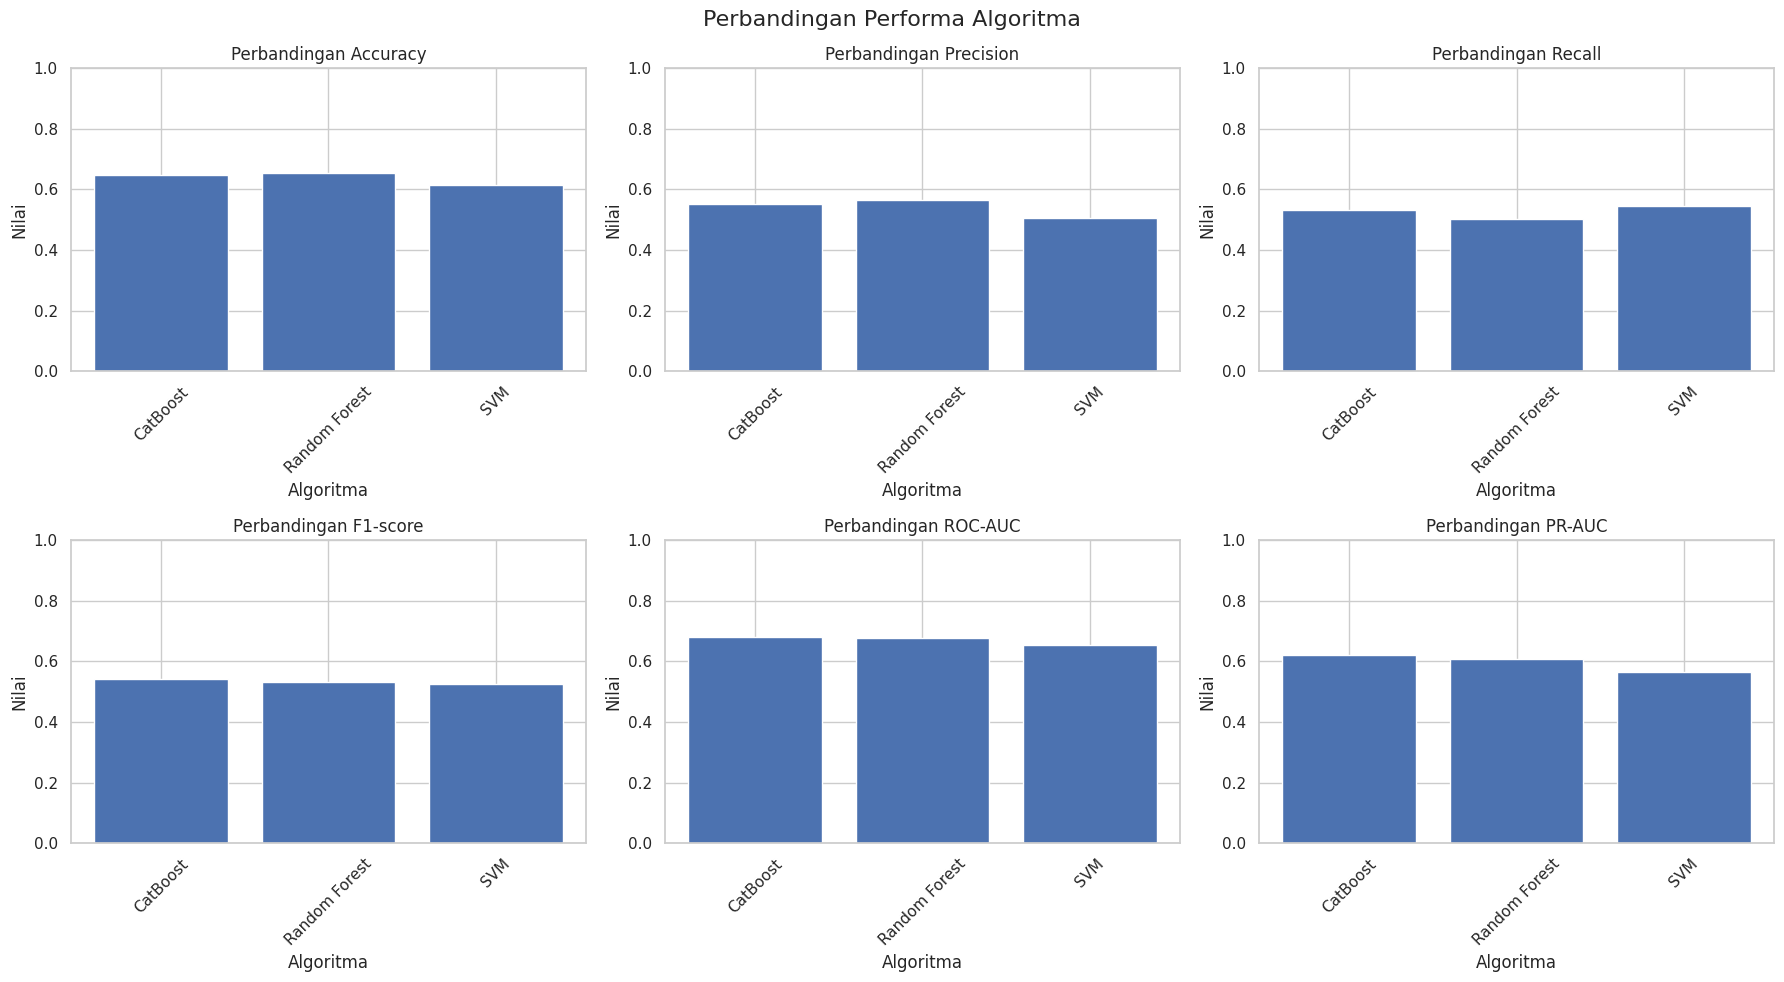

In [ ]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "PR-AUC"
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, metric in enumerate(metrics):
    axes[i].bar(
        results_df.index.astype(str),
        results_df[metric]
    )

    axes[i].set_title(f"Perbandingan {metric}")
    axes[i].set_xlabel("Algoritma")
    axes[i].set_ylabel("Nilai")
    axes[i].set_ylim(0, 1)
    axes[i].tick_params(axis="x", rotation=45)

plt.suptitle(
    "Perbandingan Performa Algoritma",
    fontsize=16
)

plt.tight_layout()
plt.show()

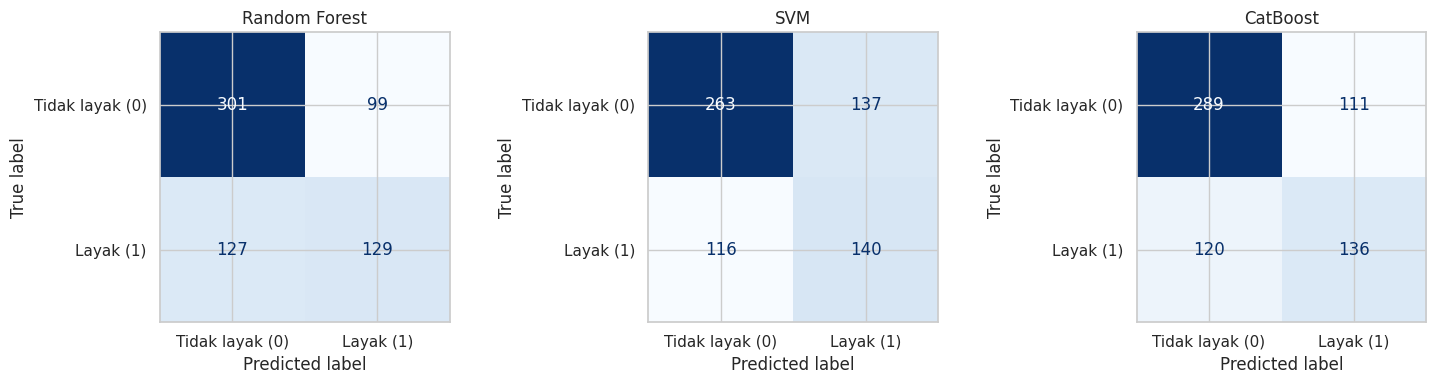

In [ ]:
fig, axes = plt.subplots(1,
    len(predictions),
    figsize=(5 * len(predictions), 4))
axes = np.atleast_1d(axes).flatten()
for ax, (name, (y_pred, _)) in zip(
    axes,predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=[
            "Tidak layak (0)",
            "Layak (1)"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

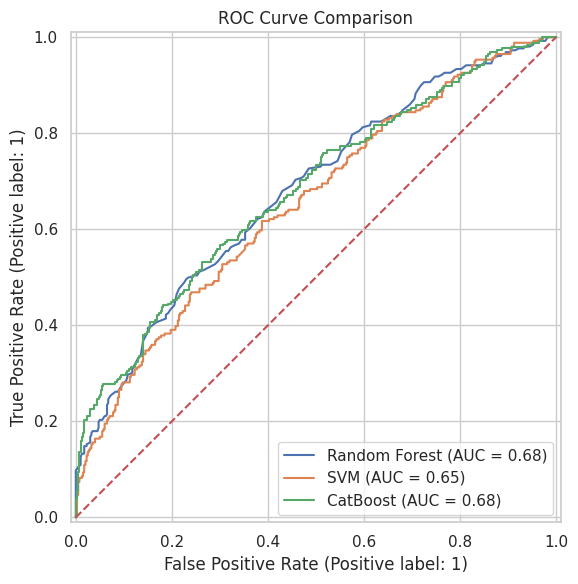

In [ ]:
fig, ax = plt.subplots(
    figsize=(8, 6))
for name, (y_pred, y_prob) in predictions.items():
    RocCurveDisplay.from_predictions(y_test,y_prob,name=name,ax=ax)

ax.plot([0, 1],[0, 1],linestyle="--",label="Random Baseline")
ax.set_title("ROC Curve Comparison")

plt.tight_layout()
plt.show()

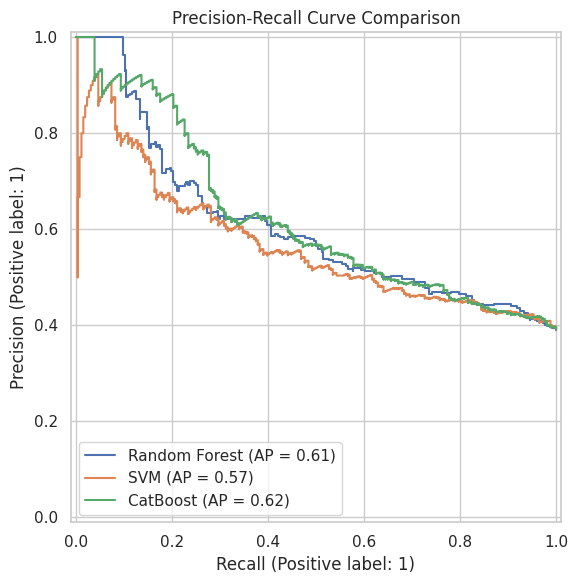

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, (y_pred, y_prob) in predictions.items():
    PrecisionRecallDisplay.from_predictions(y_test, y_prob, name=name, ax=ax)
ax.set_title("Precision-Recall Curve Comparison")
plt.tight_layout()
plt.show()

In [ ]:
for name, (y_pred, y_prob) in predictions.items():
    print("=" * 60)
    print("CLASSIFICATION REPORT:", name)
    print("=" * 60)
    print(
        classification_report(y_test,y_pred,
            target_names=["Tidak layak","Layak"],
            zero_division=0
        )
    )

CLASSIFICATION REPORT: Random Forest
              precision    recall  f1-score   support

 Tidak layak       0.70      0.75      0.73       400
       Layak       0.57      0.50      0.53       256

    accuracy                           0.66       656
   macro avg       0.63      0.63      0.63       656
weighted avg       0.65      0.66      0.65       656

CLASSIFICATION REPORT: SVM
              precision    recall  f1-score   support

 Tidak layak       0.69      0.66      0.68       400
       Layak       0.51      0.55      0.53       256

    accuracy                           0.61       656
   macro avg       0.60      0.60      0.60       656
weighted avg       0.62      0.61      0.62       656

CLASSIFICATION REPORT: CatBoost
              precision    recall  f1-score   support

 Tidak layak       0.71      0.72      0.71       400
       Layak       0.55      0.53      0.54       256

    accuracy                           0.65       656
   macro avg       0.63      0.6

**Interpretasi Visualisasi Evaluasi**

Berdasarkan confusion matrix, ROC Curve, dan Precision-Recall Curve, Random Forest menunjukkan nilai ROC-AUC tertinggi sebesar 0,68, sedangkan Gradient Boosting memperoleh Average Precision tertinggi sebesar 0,62. Kedua algoritma menunjukkan performa lebih baik dibandingkan Logistic Regression pada hasil evaluasi ini.

In [ ]:
best_model_name = results_df["F1-score"].idxmax()
print(
    "Kandidat model terbaik berdasarkan F1-score:",
    best_model_name)
print("\nHasil evaluasi:")

display(results_df.loc[best_model_name].to_frame("Score").round(4))


best_pred, best_prob = predictions[
    best_model_name
]

print("\nConfusion Matrix:")
print(
    confusion_matrix(y_test,best_pred
    )
)


best_model = models[best_model_name]
print("\nObjek model terbaik berhasil ditentukan.")

Kandidat model terbaik berdasarkan F1-score: CatBoost

Hasil evaluasi:


,Score
Accuracy,0.6479
Precision,0.5506
Recall,0.5312
F1-score,0.5408
ROC-AUC,0.6799
PR-AUC,0.6204



Confusion Matrix:
[[289 111]
 [120 136]]

Objek model terbaik berhasil ditentukan.


,Feature,Importance_Mean,Importance_Std
4,Sulfate,0.081333,0.013108
0,ph,0.075074,0.018292
2,Solids,0.060732,0.009823
3,Chloramines,0.036285,0.014175
6,Organic_carbon,0.026181,0.013776
1,Hardness,0.018245,0.011015
7,Trihalomethanes,-0.000790,0.007136
8,Turbidity,-0.014670,0.013297
5,Conductivity,-0.016494,0.017602


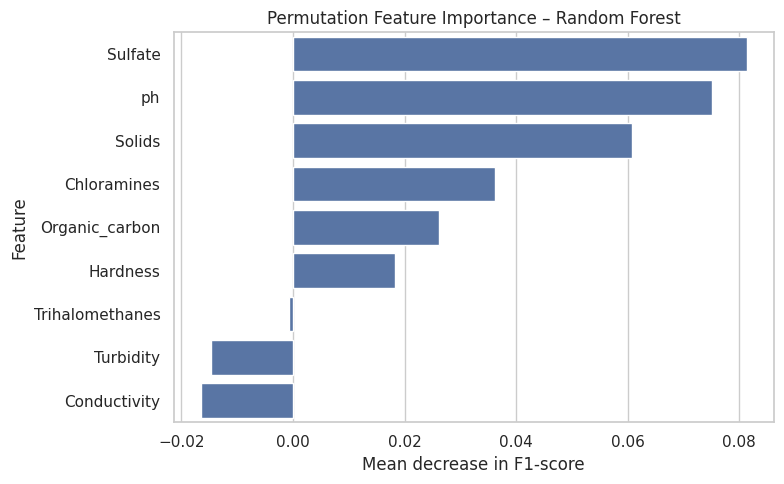

In [ ]:
tree_candidates = ["Random Forest"]
tree_model_name = max(
    tree_candidates,
    key=lambda n: results_df.loc[n, "F1-score"]
)
tree_model = models[tree_model_name]

perm = permutation_importance(
    tree_model, X_test, y_test,
    n_repeats=10,
    random_state=RANDOM_STATE,
    scoring="f1"
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm.importances_mean,
    "Importance_Std": perm.importances_std
}).sort_values("Importance_Mean", ascending=False)

display(importance_df)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df, x="Importance_Mean", y="Feature")
plt.title(f"Permutation Feature Importance – {tree_model_name}")
plt.xlabel("Mean decrease in F1-score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()